# Phase B — Individual Implementation
## Conservative LSTM with JAX

**Format:** individual, at home. Implement, train, evaluate, and reflect.

**Prerequisite:** the plan your group wrote in Phase A (`A1_Phase_A_Group_Exercise.ipynb`).

<a id='0'></a>
## 0. Environment setup

Install dependencies if you don't have them yet.

In [1]:
# Uncomment if needed (e.g. a fresh environment or Colab)
# %pip install -q "jax[cpu]" flax optax matplotlib
    
import jax
import jax.numpy as jnp
import flax.linen as nn
import optax
import numpy as np
import matplotlib.pyplot as plt
import time

print("JAX version:", jax.__version__)
print("Devices    :", jax.devices())

JAX version: 0.12.0.1
Devices    : [CpuDevice(id=0)]


<a id='1'></a>
## 1. Introduction to JAX and Flax

JAX is a numerical computing library built around a **functional** programming style. Its syntax is close to NumPy, with three key additions:

| Function | What it does |
|---|---|
| `jax.grad` | Automatic differentiation (exact gradients of any Python function) |
| `jax.jit` | Just-in-time compilation (XLA) → much faster execution |
| `jax.vmap` | Automatic vectorization over a batch axis |

Random numbers use **explicit keys** (`PRNGKey`) instead of a global seed — the same key always gives the same numbers, which makes your code fully reproducible. Neural networks are built with **Flax** (`flax.linen`, imported as `nn`), a layer on top of JAX for trainable models.

Two things to keep in mind:
- JAX functions should be **pure** (no side effects) so that `jit`/`grad` work correctly.
- JAX arrays are **immutable**: you don't modify them in place, you return new ones.

Run the demo below to see all three capabilities in action.

In [2]:
# Mini-demo of JAX's three key capabilities

# (a) Automatic differentiation
f = lambda x: x ** 3 + 2 * x
df = jax.grad(f)                # derivative: 3x^2 + 2
print("f'(2) =", df(2.0), "(expected 14.0)")

# (b) Explicit random keys -> reproducibility
key = jax.random.PRNGKey(0)
k1, k2 = jax.random.split(key)
print("Reproducible sample:", jax.random.normal(k1, (3,)))

# (c) JIT + vmap
g = jax.jit(jax.vmap(f))        # applies f to a whole vector, compiled
print("g([1,2,3]) =", g(jnp.array([1., 2., 3.])))

f'(2) = 14.0 (expected 14.0)
Reproducible sample: [ 1.0040143 -0.9063372 -0.7481722]
g([1,2,3]) = [ 3. 12. 33.]


### Flax basics for recurrent models

- A `nn.Module` describes the *computation*, not the state. You create parameters with `model.init(key, dummy_input)` (returns a `params` pytree), then run the network with `model.apply(params, x)` — `params` is always passed explicitly.
- For recurrence, Flax provides `nn.LSTMCell` (one timestep) and `nn.RNN` (unrolls a cell over a whole sequence). You'll use both below.

### Optax for optimization

```python
optimizer = optax.adam(learning_rate=1e-2)
opt_state = optimizer.init(params)

loss, grads = jax.value_and_grad(loss_fn)(params, batch)
updates, opt_state = optimizer.update(grads, opt_state, params)
params = optax.apply_updates(params, updates)
```

Wrapping this whole step in `@jax.jit` compiles it once and reuses the compiled version on every call — this is what makes JAX training loops fast.

A simple example is often enough to illustrate the Flax programming model before introducing recurrence. The following network learns a basic regression problem using a small multilayer perceptron.

In [3]:
import jax
import jax.numpy as jnp
from flax import linen as nn
import optax


# ---------------------------------------------------------
# 1. Define a simple neural network
# ---------------------------------------------------------

class SimpleMLP(nn.Module):
    hidden_size: int = 32

    # @nn.compact is a decorator in Flax that tells the framework:
    # “The layers used inside this method should be created automatically 
    # the first time the method is called.”
    # It is the most common way to define Flax models.

    @nn.compact
    def __call__(self, x):
        x = nn.Dense(self.hidden_size)(x)
        x = nn.relu(x)
        x = nn.Dense(1)(x)
        return x

# ---------------------------------------------------------
# 2. Create a synthetic regression dataset
# ---------------------------------------------------------

key = jax.random.PRNGKey(0)
key, data_key, init_key = jax.random.split(key, 3)
x_train = jax.random.normal(data_key, shape=(128, 4))
y_train = (
    2.0 * x_train[:, 0]
    - 1.5 * x_train[:, 1]
    + 0.5 * x_train[:, 2]
    + 0.2
)
y_train = y_train[:, None]

# ---------------------------------------------------------
# 3. Create the model and initialize its parameters
# ---------------------------------------------------------

model = SimpleMLP(hidden_size=16)
dummy_input = jnp.ones((1, 4))
params = model.init(init_key, dummy_input)

# ---------------------------------------------------------
# 4. Define the loss function
# ---------------------------------------------------------

def loss_fn(params, x, y):
    predictions = model.apply(params, x)
    loss = jnp.mean((predictions - y) ** 2)
    return loss

# ---------------------------------------------------------
# 5. Create the optimizer
# ---------------------------------------------------------

optimizer = optax.adam(learning_rate=1e-3)
opt_state = optimizer.init(params)

# ---------------------------------------------------------
# 6. Define one training step
# ---------------------------------------------------------

@jax.jit
def train_step(params, opt_state, x, y):
    loss, gradients = jax.value_and_grad(loss_fn)(
        params,
        x,
        y
    )
    updates, opt_state = optimizer.update(
        gradients,
        opt_state,
        params
    )
    params = optax.apply_updates(params, updates)
    return params, opt_state, loss

# ---------------------------------------------------------
# 7. Train the model
# ---------------------------------------------------------

num_epochs = 1000

for epoch in range(num_epochs):
    params, opt_state, loss = train_step(
        params,
        opt_state,
        x_train,
        y_train
    )
    if epoch % 100 == 0:
        print(f"Epoch {epoch:4d} | Loss: {float(loss):.6f}")

# ---------------------------------------------------------
# 8. Evaluate the trained model
# ---------------------------------------------------------

predictions = model.apply(params, x_train)
final_loss = jnp.mean(
    (predictions - y_train) ** 2
)
print(f"Final loss: {float(final_loss):.6f}")


# ---------------------------------------------------------
# 9. Test the model with new samples
# ---------------------------------------------------------

x_test = jnp.array([
    [1.0, 2.0, 3.0, 4.0],
    [-1.0, 0.5, 2.0, 1.0]
])
predicted_values = model.apply(params, x_test)
true_values = (
    2.0 * x_test[:, 0]
    - 1.5 * x_test[:, 1]
    + 0.5 * x_test[:, 2]
    + 0.2
)

print("\nPredictions:")
print(predicted_values.squeeze())

print("\nTrue values:")
print(true_values)

Epoch    0 | Loss: 5.076825
Epoch  100 | Loss: 2.333333
Epoch  200 | Loss: 0.558173
Epoch  300 | Loss: 0.102863
Epoch  400 | Loss: 0.051410
Epoch  500 | Loss: 0.036595
Epoch  600 | Loss: 0.029150
Epoch  700 | Loss: 0.024714
Epoch  800 | Loss: 0.022067
Epoch  900 | Loss: 0.019799
Final loss: 0.017727

Predictions:
[ 0.6405681 -1.6374569]

True values:
[ 0.7  -1.55]


<a id='2'></a>
## 2. Scientific background (recap)

Many physical systems obey **conservation laws** (mass, energy, charge, momentum, ...). A conventional neural network trained only to minimize prediction error has no notion of these laws.

Phase A (§2) asked you to compare four ways of incorporating the conservation law and to choose one for your group's plan. This notebook has you implement **two** models: the **baseline** (§5, Option 1 — direct prediction, no physical structure) and **your model** (§6 — whichever of Options 2/3/4 your group chose), then compare them. This is one instance of **physics-informed machine learning**: known structure shrinks the space of functions the network can represent, so a well-chosen architecture can be both physically valid *and* need less data to generalize well.

<a id='3'></a>
## 3. The scenario (recap)

| Symbol | Meaning | Observed? |
|---|---|---|
| `m(t)` | Water mass (volume) in the reservoir | yes |
| `r(t)` | Inflow | yes |
| `q(t)` | Controlled outflow | yes |
| `c(t)` | Hidden consumption | **no** |

$$ m(t+1) = m(t) + r(t) - q(t) - c(t) $$

As in Phase A §1, `c(t)` depends on temperature, hour of day, day of year, and its own small random noise; it is the only unobserved term in the mass balance.

Models will only ever see `x(t) = [m(t), r(t), q(t), temp(t), hour(t), day_year(t)]` as input (matching the variables Phase A identified as driving `c(t)`). The target for training is `m(t+1)`.

<a id='4'></a>
## 4. Task 5.1 — Generate synthetic sequential data

Simulate `N` independent sequences of length `T` (e.g. `N=400`, `T=480` hourly steps ≈ 20 days).

**Design notes / hints:**
- **Inflow / outflow.** The simplest valid design samples `r(t)` and `q(t)` i.i.d. from a fixed range at every timestep (e.g. `r(t) ~ U[2.0, 3.5]`, `q(t) ~ U[1.0, 2.0]`) — they don't need to be autocorrelated or seasonal, since they're always fully observed anyway.
- **Temperature.** Give it a daily cycle plus per-sequence and per-step noise, e.g.
  `temp(t) = 20 + 8·sin(2π(hour(t) − 6)/24) + offset_seq + noise(t)`, where `offset_seq` is drawn once per sequence and `noise(t)` independently at every step.
- **Day of year.** A sequence spans a small window of days (e.g. `T=480` hours ≈ 20 days), so `day_year(t)` is close to constant within a sequence but differs across sequences — draw one starting day per sequence (e.g. `U[0, 365]`) and increment it as `t` advances. Normalize to `[0, 1]` for the network input, same as `hour_norm`.
- **Hidden consumption `c(t)`.** Build it from a base level, a temperature term, and a daily usage profile, then clip to non-negative:

  ```
  hour_profile(t) = 0.5 · (1 + sin(2π(hour(t) − 8)/24))   # peaks around midday/evening
  c_raw(t)        = c0 + α·(temp(t) − mean(temp)) + β·hour_profile(t) + noise_c(t)
  c(t)            = max(0, c_raw(t))                       # consumption can't be negative
  ```

  (e.g. `c0=1.0`, `α=0.05`, `β=1.2`, small-amplitude `noise_c`). Note it's the **clipping**, not the formula itself, that enforces non-negativity. (You could also make `c0`/`α`/`β` depend on `day_year(t)` — e.g. a seasonal component — but a constant base level is enough to complete the task.)
- Roll the mass forward: pick `m(0)` (e.g. `100 + U[0,10]`), then apply `m(t+1) = m(t) + r(t) - q(t) - c(t)` step by step to build the whole sequence.
- Store `X = [m, r, q, temp, hour_norm, day_year_norm]` (that feature order), `Y = m(t+1)`, and `C` (true hidden consumption, diagnostics only).

**Implementation of the generator.** ★
- Every quantity is built for all sequences and time steps at once, as arrays of shape `(n_seq, T)`. The values drawn once per sequence (`h0`, `d0`, `offset_seq`, `m(0)`) have shape `(n_seq, 1)` and broadcast over time.
- The mass is not rolled forward in a Python loop: since `m(t+1) = m(t) + r(t) − q(t) − c(t)`, the whole trajectory is `m(0)` plus the **cumulative sum** of the net flow. The balance therefore holds exactly (up to float32 rounding).
- `c(t)` is **clipped** at 0 because consumption only removes water; the linear formula alone could go negative on a cold night with negative noise.
- Two values differ from the template's examples: `r ~ U[2.35, 3.85]` and `m(0) = 150 + U[0, 10]`. With the suggested ones the reservoir drains by about 0.35 per hour and the volume goes negative within a sequence.
- The key is split into **one sub-key per random quantity**, so no key is used twice and the same key always gives the same data.

In [4]:
def generate_data(key, n_seq=400, T=480):
    """Generate n_seq sequences of length T for the water-reservoir system.

    Returns
    -------
    X : (n_seq, T, 6) array -> [m, r, q, temp, hour_norm, day_year_norm]
    Y : (n_seq, T)    array -> m(t+1)
    C : (n_seq, T)    array -> true hidden consumption (diagnostics only)
    """
    k_h0, k_d0, k_r, k_q, k_off, k_tn, k_c, k_m0 = jax.random.split(key, 8)
    t = jnp.arange(T)

    # Calendar: one random start per sequence, then advance hour by hour
    h0 = jax.random.randint(k_h0, (n_seq, 1), 0, 24)
    hour = (h0 + t) % 24                                              # (n_seq, T)
    d0 = jax.random.uniform(k_d0, (n_seq, 1), minval=0.0, maxval=365.0)
    day_year = (d0 + t / 24.0) % 365.0

    # Observed flows, i.i.d. at every step
    r = jax.random.uniform(k_r, (n_seq, T), minval=2.35, maxval=3.85)
    q = jax.random.uniform(k_q, (n_seq, T), minval=1.0, maxval=2.0)

    # Temperature: daily cycle + per-sequence offset + per-step noise
    offset_seq = jax.random.normal(k_off, (n_seq, 1))
    temp = (20.0 + 8.0 * jnp.sin(2 * jnp.pi * (hour - 6) / 24)
            + offset_seq + jax.random.normal(k_tn, (n_seq, T)))

    # Hidden consumption, clipped to be non-negative
    hour_profile = 0.5 * (1 + jnp.sin(2 * jnp.pi * (hour - 8) / 24))
    noise_c = 0.1 * jax.random.normal(k_c, (n_seq, T))
    c = jnp.maximum(0.0, 1.0 + 0.05 * (temp - 20.0) + 1.2 * hour_profile + noise_c)

    # Mass balance: m(t+1) = m(0) + cumulative sum of the net flow
    m0 = 150.0 + jax.random.uniform(k_m0, (n_seq, 1), minval=0.0, maxval=10.0)
    m_next = m0 + jnp.cumsum(r - q - c, axis=1)                       # m(t+1)
    m = jnp.concatenate([m0, m_next[:, :-1]], axis=1)                 # m(t)

    X = jnp.stack([m, r, q, temp, hour / 24.0, day_year / 365.0], axis=-1)
    return X, m_next, c

key = jax.random.PRNGKey(112358)
key, kdata = jax.random.split(key)
X, Y, C = generate_data(kdata)
print("X:", X.shape, " Y:", Y.shape, " C:", C.shape)

balance_residual = float(jnp.max(jnp.abs(Y - (X[..., 0] + X[..., 1] - X[..., 2] - C))))
print(f"C >= 0: {bool(jnp.all(C >= 0))} | m range: [{float(X[..., 0].min()):.1f}, {float(X[..., 0].max()):.1f}]"
      f" | max balance residual: {balance_residual:.2e}")
assert X.shape == (400, 480, 6) and Y.shape == (400, 480) and C.shape == (400, 480)
assert bool(jnp.all(C >= 0)) and bool(jnp.all(X[..., 0] > 0)) and balance_residual < 1e-3
assert bool(jnp.array_equal(generate_data(kdata)[0], X)), "same key must give the same data"

X: (400, 480, 6)  Y: (400, 480)  C: (400, 480)
C >= 0: True | m range: [80.2, 234.2] | max balance residual: 3.05e-05


**Sanity check.** One simulated sequence: the mass over the 20 days (top), and the three flows over the first 5 days (bottom), so the daily cycle of the hidden consumption `c(t)` is visible next to the i.i.d. flows `r` and `q`.

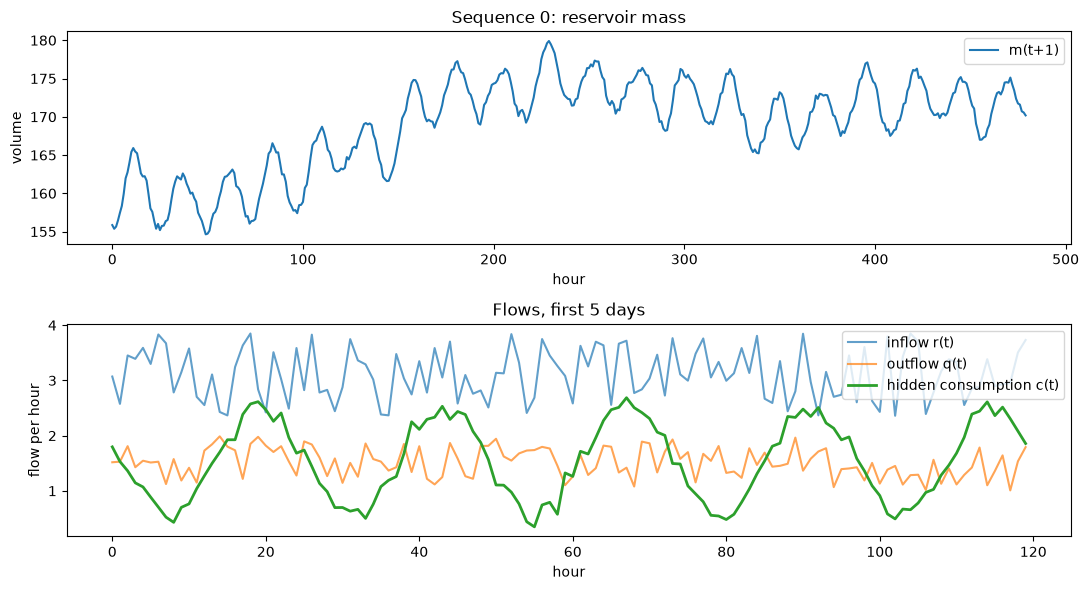

In [5]:
seq = 0
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6))
ax1.plot(Y[seq], label="m(t+1)")
ax1.set(xlabel="hour", ylabel="volume", title=f"Sequence {seq}: reservoir mass")
ax1.legend()
hours = slice(0, 120)
ax2.plot(X[seq, hours, 1], label="inflow r(t)", alpha=0.7)
ax2.plot(X[seq, hours, 2], label="outflow q(t)", alpha=0.7)
ax2.plot(C[seq, hours], label="hidden consumption c(t)", lw=2)
ax2.set(xlabel="hour", ylabel="flow per hour", title="Flows, first 5 days")
ax2.legend(loc="upper right")
plt.tight_layout()
plt.show()

**Split and normalize.** Split train/test **by sequence**, not by timestep, so no timesteps from a test sequence leak into training through shared history. Normalize inputs (zero mean, unit variance) using statistics computed **only on the training split**. Keep the *unnormalized* `m(t)`, `r(t)`, `q(t)` around separately — you'll need the raw physical values later for the conservation-law reconstruction, which must not be done in normalized units.

**Implementation of the split and normalization.** ★
- **By sequence:** the first 300 sequences train, the last 100 test. Splitting by time step would put the past of a test step in the training set, and the LSTM's hidden state carries that history, so the test score would be optimistic.
- **Training statistics only:** `x_mean`, `x_std` (one value per feature, over all training sequences and steps) and `y_mean`, `y_std` are computed on the training split. Using the test set here would leak information about it.
- `norm_x` is used **only for the network input** (`Xn_tr`, `Xn_te`). The raw `X_tr`, `X_te` are kept: the mass balance of Option 4 needs `m, r, q` in physical units.
- `y_mean`, `y_std` are used only to map the baseline's output back to physical units (§5).

In [6]:
n_train = 300

X_tr, X_te = X[:n_train], X[n_train:]
Y_tr, Y_te = Y[:n_train], Y[n_train:]
C_tr, C_te = C[:n_train], C[n_train:]

x_mean = X_tr.reshape(-1, 6).mean(axis=0)
x_std = X_tr.reshape(-1, 6).std(axis=0)
def norm_x(x):
    """Standardize the inputs with the training statistics."""
    return (x - x_mean) / x_std

Xn_tr, Xn_te = norm_x(X_tr), norm_x(X_te)
y_mean, y_std = Y_tr.mean(), Y_tr.std()

print("train:", X_tr.shape, " test:", X_te.shape)
print("normalized train mean:", np.round(np.asarray(Xn_tr.reshape(-1, 6).mean(0)), 4))
print("normalized train std :", np.round(np.asarray(Xn_tr.reshape(-1, 6).std(0)), 4))
print(f"y_mean = {float(y_mean):.2f}, y_std = {float(y_std):.2f}")
assert X_tr.shape == (300, 480, 6) and X_te.shape == (100, 480, 6)
assert jnp.allclose(Xn_tr.reshape(-1, 6).mean(0), 0, atol=1e-3) and jnp.allclose(Xn_tr.reshape(-1, 6).std(0), 1, atol=1e-3)

train: (300, 480, 6)  test: (100, 480, 6)
normalized train mean: [-0. -0.  0. -0. -0. -0.]
normalized train std : [1. 1. 1. 1. 1. 1.]
y_mean = 154.82, y_std = 16.60


<a id='5'></a>
## 5. Task 5.2 — Conventional LSTM (the baseline, Option 1)

A standard LSTM that receives the observable variables and **predicts the mass directly**:

$$ \hat{m}(t+1) = \text{LSTM}_\theta\big(x(t)\big) $$

It has no knowledge of the conservation law — it has to learn everything from data. This is your baseline.

**Implementation of the baseline.** ★
- `LSTMBackbone` wraps one `nn.LSTMCell` in `nn.RNN`, which scans the cell over the time axis and returns the hidden state at **every** step, shape `(batch, T, 32)`. The state at step `t` has seen `x(0), …, x(t)` only, so each prediction uses the past and present, never the future.
- `ConventionalLSTM` adds one `Dense(1)` per step and squeezes the last axis: one output per step, `(batch, T)` (many-to-many).
- The module is the template's. Its output is mapped to physical units in `predict_baseline` with the fixed training statistics: `m̂ = y_mean + y_std · output`. The raw output stays small while the target is around 155; without this scaling the baseline does not converge in 300 epochs, and the comparison would measure output scaling instead of physics. The scaling is fixed, not learned, and contains no physics.

In [7]:
class LSTMBackbone(nn.Module):
    """Recurrent LSTM layer returning the hidden state at every step."""
    hidden_size: int = 32

    @nn.compact
    def __call__(self, xs):                     # xs: (batch, T, features)
        return nn.RNN(nn.LSTMCell(features=self.hidden_size))(xs)   # (batch, T, hidden)


class ConventionalLSTM(nn.Module):
    """Predicts m(t+1) directly."""
    hidden_size: int = 32

    @nn.compact
    def __call__(self, xs):                     # xs (normalized): (batch, T, 6)
        h = LSTMBackbone(self.hidden_size)(xs)
        return nn.Dense(1)(h).squeeze(-1)       # (batch, T)

Create the baseline and its parameters with a fresh sub-key, define `predict_baseline`, and check the output shape and the parameter count on two training sequences.

In [8]:
HIDDEN_SIZE = 32

def n_params(params):
    """Total number of scalar parameters in a pytree."""
    return sum(p.size for p in jax.tree_util.tree_leaves(params))

conv_model = ConventionalLSTM(hidden_size=HIDDEN_SIZE)
key, k_init_conv = jax.random.split(key)
conv_params = conv_model.init(k_init_conv, Xn_tr[:1])

def predict_baseline(params, xn):
    """Baseline prediction of m(t+1) in physical units."""
    return y_mean + y_std * conv_model.apply(params, xn)

out = predict_baseline(conv_params, Xn_tr[:2])
print("output:", out.shape, "| parameters:", n_params(conv_params))
assert out.shape == (2, 480) and n_params(conv_params) == 5025

output: (2, 480) | parameters: 5025


<a id='6'></a>
## 6. Task 5.3 — Your model (the option your group chose in Phase A)

Implement **one** of the three non-baseline options from Phase A §2 — whichever your group chose and justified in Discussion 3. You only need the one matching your choice; the other two stubs below are there for reference (or if you want to compare more than one — optional, not required).

**Important, for all three options:** the model should receive `xs` **normalized** for the neural-network part, but must use the **original physical values** of `m`, `r`, `q` wherever the mass balance is used (reconstruction, or the physics loss term) — doing that arithmetic in normalized units would be physically meaningless.

### Option 2 — Soft constraint

Two outputs, `(m̂(t+1), ĉ(t))`, both learned — nothing in the architecture enforces the conservation law. Instead, an extra loss term penalizes violations:

$$ L = L_{\text{pred}} + \lambda\, L_{\text{physics}}, \qquad
L_{\text{pred}} = \big(\hat m(t{+}1)-m(t{+}1)\big)^2, \qquad
L_{\text{physics}} = \big(\hat m(t{+}1)-m(t)-r(t)+q(t)+\hat c(t)\big)^2 $$

`λ` is a new hyperparameter you choose — see §7 for how it plugs into training.

In [9]:
class SoftConstraintLSTM(nn.Module):
    """Option 2: predicts (m_hat, c_hat); conservation is only encouraged via the loss (see Sec.7)."""
    hidden_size: int = 32

    @nn.compact
    def __call__(self, xs_norm):
        # xs_norm: normalized network input (batch, T, 6)
        # TODO:
        #   1. h = LSTMBackbone(...)(xs_norm)
        #   2. two separate Dense(1) heads on h -> m_hat, c_hat, each squeezed to (batch, T)
        #   3. return m_hat, c_hat
        raise NotImplementedError


### Option 3 — Hard constraint (conservative architecture)

The network predicts only the hidden consumption; the mass is reconstructed analytically, so conservation holds exactly by construction:

$$ \hat{c}(t) = \text{softplus}\big(\text{LSTM}_\theta(x(t))\big) \ge 0
\qquad\Longrightarrow\qquad
\hat{m}(t+1) = m(t) + r(t) - q(t) - \hat{c}(t) $$

`softplus` is preferred over `relu` here: it's smooth and differentiable everywhere, so it won't stall learning at `ĉ=0`.

In [10]:
class ConservativeLSTM(nn.Module):
    """Option 3: predicts hidden consumption c_hat(t) >= 0 and closes the mass balance exactly."""
    hidden_size: int = 32

    @nn.compact
    def __call__(self, xs_norm, m_phys, r_phys, q_phys):
        # xs_norm: normalized network input          (batch, T, 6)
        # m_phys, r_phys, q_phys: RAW physical values (batch, T)
        # TODO:
        #   1. h = LSTMBackbone(...)(xs_norm)
        #   2. c_raw = Dense(1) head on h, squeeze to (batch, T)
        #   3. c_hat = nn.softplus(c_raw)              # hard positivity constraint
        #   4. m_pred = m_phys + r_phys - q_phys - c_hat
        #   5. return m_pred, c_hat
        raise NotImplementedError


### Option 4 — Residual correction

Like Option 3, but the network also predicts a small correction `δ(t)` to absorb unmodelled effects:

$$ \hat{m}(t+1) = m(t) + r(t) - q(t) - \hat{c}(t) + \delta(t) $$

Useful if you think the conservation law alone doesn't fully capture the true dynamics — but conservation is no longer exact, so watch how large `δ(t)` grows in §8's physical-error metric.

**Implementation of Option 4 (residual correction).** ★
- The same `LSTMBackbone` feeds **two heads**, one `Dense(1)` each: one for the consumption, one for the correction.
- `ĉ = softplus(·) > 0`: consumption can't be negative, and `softplus` is smooth, so gradients never stop at 0 as they would with `relu`.
- `δ` has **no constraint**: it can absorb whatever the balance misses, in either direction.
- The next mass is computed, not predicted: `m̂ = m + r − q − ĉ + δ`, with the **raw** `m, r, q`. Only the LSTM input is normalized.
- `δ` is what makes conservation approximate: the implied consumption is `ĉ − δ`, which is negative whenever `δ > ĉ`. Only `ĉ − δ` enters `m̂`, so the loss cannot separate `ĉ` from `δ`.

In [11]:
class ResidualCorrectionLSTM(nn.Module):
    """Option 4: hard constraint plus a small learned correction delta(t)."""
    hidden_size: int = 32

    @nn.compact
    def __call__(self, xs_norm, m_phys, r_phys, q_phys):
        # xs_norm: normalized network input          (batch, T, 6)
        # m_phys, r_phys, q_phys: RAW physical values (batch, T)
        h = LSTMBackbone(self.hidden_size)(xs_norm)
        c_hat = nn.softplus(nn.Dense(1)(h).squeeze(-1))    # hidden consumption, > 0
        delta = nn.Dense(1)(h).squeeze(-1)                 # correction, unconstrained
        m_pred = m_phys + r_phys - q_phys - c_hat + delta  # mass balance in physical units
        return m_pred, c_hat, delta

Create Option 4 and its parameters with a fresh sub-key, and check it before training: three outputs of shape `(2, 480)`, 33 more parameters than the baseline (the second head), `ĉ > 0`, and `m̂` equal to the balance.

In [12]:
res_model = ResidualCorrectionLSTM(hidden_size=HIDDEN_SIZE)
key, k_init_res = jax.random.split(key)
res_params = res_model.init(k_init_res, Xn_tr[:1], X_tr[:1, :, 0], X_tr[:1, :, 1], X_tr[:1, :, 2])

m_pred, c_hat, delta = res_model.apply(res_params, Xn_tr[:2], X_tr[:2, :, 0], X_tr[:2, :, 1], X_tr[:2, :, 2])
gap = float(jnp.max(jnp.abs(m_pred - (X_tr[:2, :, 0] + X_tr[:2, :, 1] - X_tr[:2, :, 2] - c_hat + delta))))
print("outputs:", m_pred.shape, c_hat.shape, delta.shape, "| parameters:", n_params(res_params),
      f"| min c_hat: {float(c_hat.min()):.3f} | balance gap: {gap:.1e}")
assert m_pred.shape == c_hat.shape == delta.shape == (2, 480) and n_params(res_params) == 5058
assert bool(jnp.all(c_hat > 0)) and gap < 1e-3

outputs: (2, 480) (2, 480) (2, 480) | parameters: 5058 | min c_hat: 0.459 | balance gap: 0.0e+00


<a id='7'></a>
## 7. Task 5.4 — Train the baseline model and your model under identical conditions

- **Baseline (§5, Option 1):** MSE on `m(t+1)` directly.
- **Your model (§6):** the loss depends on which option you implemented —
  - **Option 2 (soft constraint):** `L = L_pred + λ·L_physics` (§6). `λ` is an extra hyperparameter — try a few values (e.g. `0.1, 1.0, 10.0`) and see how it trades off prediction accuracy against conservation.
  - **Option 3 (hard constraint) / Option 4 (residual correction):** MSE on the *reconstructed* `m̂(t+1)`, not on `ĉ(t)` directly — the true `c(t)` must not be used for supervision.
- Same optimizer, learning rate, hidden size, and number of epochs for both models — otherwise you're no longer measuring the effect of the architecture alone. Reasonable starting values: `hidden_size=32`, `Adam(learning_rate=1e-2)`, `~300` epochs, `batch_size=32` sequences.
- **Use mini-batch training**: at each step, sample (or shuffle-and-slice) a batch of `batch_size` sequences from the training set rather than using all sequences at once. Reshuffle sequence order at the start of every epoch, using `jax.random.permutation` (splitting your key each time) so the shuffling stays reproducible.
- Wrap the training step in `jax.jit` and record training time for both models.
- Plot training loss curves for both on the same axes (log scale is usually clearer).

**Implementation of the training loop.** ★
- `make_train_step` (given) builds **one** jitted step per training run: XLA compiles it on the first call and reuses it for every batch.
- Each epoch splits the key and draws a fresh `jax.random.permutation` of the 300 training sequences, so the shuffling differs every epoch but is reproducible.
- The permutation is cut into batches of exactly 32 **whole sequences** (9 per epoch). The last 12 sequences of each permutation are dropped: they change every epoch, and keeping one batch shape means the step is compiled only once.
- A batch is the dict `{"xn", "y", **extra}`. The loss is differentiated with respect to the parameters only; the epoch loss is the mean of the batch losses, converted to a Python float.
- `model` is not used inside: the loss functions already know their model. It stays to keep the template's signature.

In [13]:
def make_train_step(loss_fn, optimizer):
    @jax.jit
    def step(params, opt_state, batch):
        loss, grads = jax.value_and_grad(loss_fn)(params, batch)
        updates, opt_state = optimizer.update(grads, opt_state, params)
        params = optax.apply_updates(params, updates)
        return params, opt_state, loss
    return step

HIDDEN_SIZE = 32
EPOCHS = 300
BATCH_SIZE = 32
optimizer = optax.adam(1e-2)

def train_model(model, params, loss_fn, key, X_xs, extra_arrays, y, epochs=EPOCHS, batch_size=BATCH_SIZE):
    """extra_arrays: dict of any additional per-batch arrays the loss_fn needs
    (e.g. {'m': m_phys, 'r': r_phys, 'q': q_phys} for the conservative model)."""
    opt_state = optimizer.init(params)
    step = make_train_step(loss_fn, optimizer)          # built once, compiled on first call
    n_batches = X_xs.shape[0] // batch_size              # full batches only
    losses = []
    for epoch in range(epochs):
        key, k_perm = jax.random.split(key)
        perm = jax.random.permutation(k_perm, X_xs.shape[0])
        batch_losses = []
        for b in range(n_batches):
            idx = perm[b * batch_size:(b + 1) * batch_size]
            batch = {"xn": X_xs[idx], "y": y[idx], **{k: v[idx] for k, v in extra_arrays.items()}}
            params, opt_state, loss = step(params, opt_state, batch)
            batch_losses.append(loss)
        losses.append(float(jnp.mean(jnp.stack(batch_losses))))
    return params, losses

**The two losses**, both the MSE of `m(t+1)` in physical units, so their curves are comparable. Option 4 is trained on the **reconstructed** mass: the gradient flows back through the balance into `ĉ` and `δ`, and the consumption is learned without ever being a target. The true `C` appears in neither loss nor in any batch. A 2-epoch trial run of each model checks the wiring; its parameters are discarded.

In [14]:
def conv_loss(params, batch):
    """Baseline: MSE of the predicted m(t+1)."""
    return jnp.mean((predict_baseline(params, batch["xn"]) - batch["y"]) ** 2)

def res_loss(params, batch):
    """Option 4: MSE of the m(t+1) reconstructed from the balance."""
    m_pred, _, _ = res_model.apply(params, batch["xn"], batch["m"], batch["r"], batch["q"])
    return jnp.mean((m_pred - batch["y"]) ** 2)

extra_conv = {}
extra_res = {"m": X_tr[..., 0], "r": X_tr[..., 1], "q": X_tr[..., 2]}

key, k_trial_conv, k_trial_res = jax.random.split(key, 3)
_, trial_conv = train_model(conv_model, conv_params, conv_loss, k_trial_conv, Xn_tr, extra_conv, Y_tr, epochs=2)
_, trial_res = train_model(res_model, res_params, res_loss, k_trial_res, Xn_tr, extra_res, Y_tr, epochs=2)
print("trial losses  baseline:", np.round(trial_conv, 3), " Option 4:", np.round(trial_res, 3))
assert np.all(np.isfinite(trial_conv + trial_res)) and trial_conv[1] < trial_conv[0] and trial_res[1] < trial_res[0]

trial losses  baseline: [156.145  42.161]  Option 4: [0.543 0.097]


**Train the baseline** for 300 epochs, timed with `time.time()`. The time includes the one-off compilation of the step (a few seconds), as it will for Option 4.

In [15]:
# --- BASELINE model (Option 1, Sec.5) ---
key, k_train_conv = jax.random.split(key)
t0 = time.time()
conv_params, conv_losses = train_model(conv_model, conv_params, conv_loss, k_train_conv,
                                       Xn_tr, extra_conv, Y_tr, epochs=EPOCHS, batch_size=BATCH_SIZE)
conv_time = time.time() - t0
print(f"Baseline: loss {conv_losses[0]:.3f} (epoch 1) -> {conv_losses[-1]:.4f} (epoch {EPOCHS}), time {conv_time:.1f} s")
assert conv_losses[-1] < conv_losses[0]

Baseline: loss 164.831 (epoch 1) -> 0.0152 (epoch 300), time 129.4 s


**Train Option 4** with exactly the same settings: optimizer, learning rate, hidden size, epochs and batch size.

In [16]:
# --- YOUR MODEL (Sec.6 -- Option 4, residual correction) ---
key, k_train_res = jax.random.split(key)
t0 = time.time()
res_params, res_losses = train_model(res_model, res_params, res_loss, k_train_res,
                                     Xn_tr, extra_res, Y_tr, epochs=EPOCHS, batch_size=BATCH_SIZE)
res_time = time.time() - t0
print(f"Option 4: loss {res_losses[0]:.3f} (epoch 1) -> {res_losses[-1]:.4f} (epoch {EPOCHS}), time {res_time:.1f} s")
assert res_losses[-1] < res_losses[0]

Option 4: loss 0.543 (epoch 1) -> 0.0100 (epoch 300), time 123.9 s


**Training curves** of both models on the same log-scale axes. Both losses are the MSE of `m(t+1)` in physical units, so the curves can be compared directly.

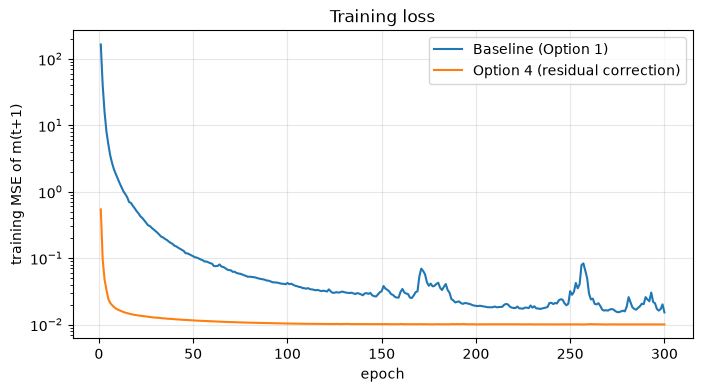

In [17]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS + 1), conv_losses, label="Baseline (Option 1)")
plt.plot(range(1, EPOCHS + 1), res_losses, label="Option 4 (residual correction)")
plt.yscale("log")
plt.xlabel("epoch"); plt.ylabel("training MSE of m(t+1)"); plt.title("Training loss")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

<a id='8'></a>
## 8. Metrics and comparison

Compute all four metrics on the **held-out test set** for both models:

| Metric | Formula |
|---|---|
| **MSE** | `mean((m̂(t+1) - m(t+1))^2)` |
| **MAE** | `mean(\|m̂(t+1) - m(t+1)\|)` |
| **Physical error** | `mean(max(0, -(m(t) + r(t) - q(t) - m̂(t+1))))` — magnitude of implied negative consumption |
| **Training time** | wall-clock time for the training loop |

**Expected pattern (depends on which option you implemented in §6):**
- The **baseline** (Option 1) should show a non-zero physical error — nothing stops it from implying negative consumption.
- **Option 2 (soft constraint):** physical error should be *reduced* relative to the baseline but generally still nonzero — how much depends on `λ`; larger `λ` should push it closer to zero, at some cost to MSE.
- **Option 3 (hard constraint):** physical error should be **exactly zero**, always — not just small. `softplus` guarantees `ĉ(t) ≥ 0`, so the implied consumption `m(t)+r(t)-q(t)-m̂(t+1) = ĉ(t)` can never be negative, regardless of training quality.
- **Option 4 (residual correction):** unlike Option 3, `δ(t)` has no positivity constraint, so physical error is generally nonzero — if `δ(t)` grows large, it can exceed Option 3's.

If your results don't roughly match the pattern for your chosen option, check: are both models trained under identical conditions? Does your model's mass computation (or physics loss term) use raw, unnormalized `m, r, q`? Is `c(t)` leaking into either model's inputs anywhere?

**Implementation of the metrics.** ★
- MSE and MAE measure **accuracy** of `m̂(t+1)` on the 100 test sequences.
- The **physical error** measures consistency. Any prediction implies a consumption `m + r − q − m̂`. Only a negative one is impossible (water appearing from nowhere), so the error is **one-sided**: `max(0, −implied)`, averaged over all steps. A model that overestimates consumption is less accurate but not unphysical.
- Next to it, the **share of steps** with a negative implied consumption says how often the law is broken, while the physical error says by how much on average.
- For Option 4 the implied consumption is exactly `ĉ − δ`.

In [18]:
def compute_metrics(m_pred, m, r, q, y):
    """Return (mse, mae, physical_error) — see formulas above."""
    mse = float(jnp.mean((m_pred - y) ** 2))
    mae = float(jnp.mean(jnp.abs(m_pred - y)))
    physical_error = float(jnp.mean(jnp.maximum(0.0, -(m + r - q - m_pred))))
    return mse, mae, physical_error

def violation_share(m_pred, m, r, q):
    """Fraction of steps whose implied consumption is negative."""
    return float(jnp.mean((m + r - q - m_pred) < 0))

m_te, r_te, q_te = X_te[..., 0], X_te[..., 1], X_te[..., 2]
pred_conv = predict_baseline(conv_params, Xn_te)
pred_res, c_hat_te, delta_te = res_model.apply(res_params, Xn_te, m_te, r_te, q_te)

results = {}
for name, pred, t_train in [("Baseline", pred_conv, conv_time), ("Option 4", pred_res, res_time)]:
    mse, mae, phys = compute_metrics(pred, m_te, r_te, q_te, Y_te)
    results[name] = dict(mse=mse, mae=mae, phys=phys, share=violation_share(pred, m_te, r_te, q_te), time=t_train)

print(f"{'Metric (test set)':<34}{'Baseline':>14}{'Option 4':>14}")
for label, k, fmt, scale in [("MSE", "mse", ".4f", 1), ("MAE", "mae", ".4f", 1), ("Physical error", "phys", ".2e", 1),
                             ("Steps with negative implied c (%)", "share", ".3f", 100), ("Training time (s)", "time", ".1f", 1)]:
    a, b = scale * results["Baseline"][k], scale * results["Option 4"][k]
    print(f"{label:<34}{a:>14{fmt}}{b:>14{fmt}}")

assert all(np.isfinite(v) for res in results.values() for v in res.values())
assert results["Option 4"]["mse"] < results["Baseline"]["mse"]

b, o = results["Baseline"], results["Option 4"]
print(f"\nReading: Option 4's test MSE is {b['mse'] / o['mse']:.1f}x lower than the baseline's.")
print(f"Baseline physical error {b['phys']:.2e} ({b['share']:.3%} of steps imply negative consumption): "
      + ("non-zero, as expected." if b["phys"] > 0 else "zero on this test set, but nothing in the model guarantees it."))
print(f"Option 4 physical error {o['phys']:.2e} ({o['share']:.3%} of steps): "
      + ("zero here, a result of the fit, not a guarantee (delta is unconstrained)." if o["phys"] == 0
         else "non-zero, possible because delta is unconstrained."))

Metric (test set)                       Baseline      Option 4
MSE                                       0.0169        0.0100
MAE                                       0.0948        0.0800
Physical error                          4.74e-05      0.00e+00
Steps with negative implied c (%)          0.017         0.000
Training time (s)                          129.4         123.9

Reading: Option 4's test MSE is 1.7x lower than the baseline's.
Baseline physical error 4.74e-05 (0.017% of steps imply negative consumption): non-zero, as expected.
Option 4 physical error 0.00e+00 (0.000% of steps): zero here, a result of the fit, not a guarantee (delta is unconstrained).


**Option 4 diagnostics.** ★ This is the only cell where the true consumption `C_te` is used, to check what the model learned, never to train it.
- `│δ│` (mean and maximum) shows how much the correction does.
- The loss only sees `ĉ − δ`, so `ĉ` and `δ` are **not identified separately**: a constant can move from one to the other without changing `m̂`. The MAE of `ĉ` alone against the true `c` can therefore be large even when the model is accurate.
- The MAE of the **effective consumption** `ĉ − δ` against the true `c` is the identified quantity, and the fair measure of how well the hidden process was recovered.

In [19]:
abs_delta = jnp.abs(delta_te)
eff_c = c_hat_te - delta_te
diag = dict(delta_mean=float(delta_te.mean()), delta_abs_mean=float(abs_delta.mean()), delta_abs_max=float(abs_delta.max()),
            mae_c_hat=float(jnp.mean(jnp.abs(c_hat_te - C_te))), mae_eff=float(jnp.mean(jnp.abs(eff_c - C_te))))
print(f"mean delta: {diag['delta_mean']:.3f} | mean |delta|: {diag['delta_abs_mean']:.3f} | max |delta|: {diag['delta_abs_max']:.3f}")
print(f"MAE of c_hat vs true c:          {diag['mae_c_hat']:.3f}")
print(f"MAE of c_hat - delta vs true c:  {diag['mae_eff']:.3f}")

print("\nInterpretation:")
if diag["delta_abs_mean"] > 0.1:
    print(f"- delta is not small (mean |delta| = {diag['delta_abs_mean']:.3f}), so c_hat alone is NOT the recovered consumption "
          f"(MAE {diag['mae_c_hat']:.3f}).")
else:
    print(f"- delta is small (mean |delta| = {diag['delta_abs_mean']:.3f}), so c_hat itself is close to the effective consumption.")
print(f"- The effective consumption c_hat - delta tracks the true c with MAE {diag['mae_eff']:.3f}, "
      f"close to the noise in c (std 0.1, mean absolute value about 0.08).")

mean delta: -0.757 | mean |delta|: 0.760 | max |delta|: 1.654
MAE of c_hat vs true c:          0.763
MAE of c_hat - delta vs true c:  0.080

Interpretation:
- delta is not small (mean |delta| = 0.760), so c_hat alone is NOT the recovered consumption (MAE 0.763).
- The effective consumption c_hat - delta tracks the true c with MAE 0.080, close to the noise in c (std 0.1, mean absolute value about 0.08).


**Plots on one test sequence:** the prediction error of both models over the 20 days, then the first week of `ĉ`, `ĉ − δ` and the true `c`, and of `δ`.

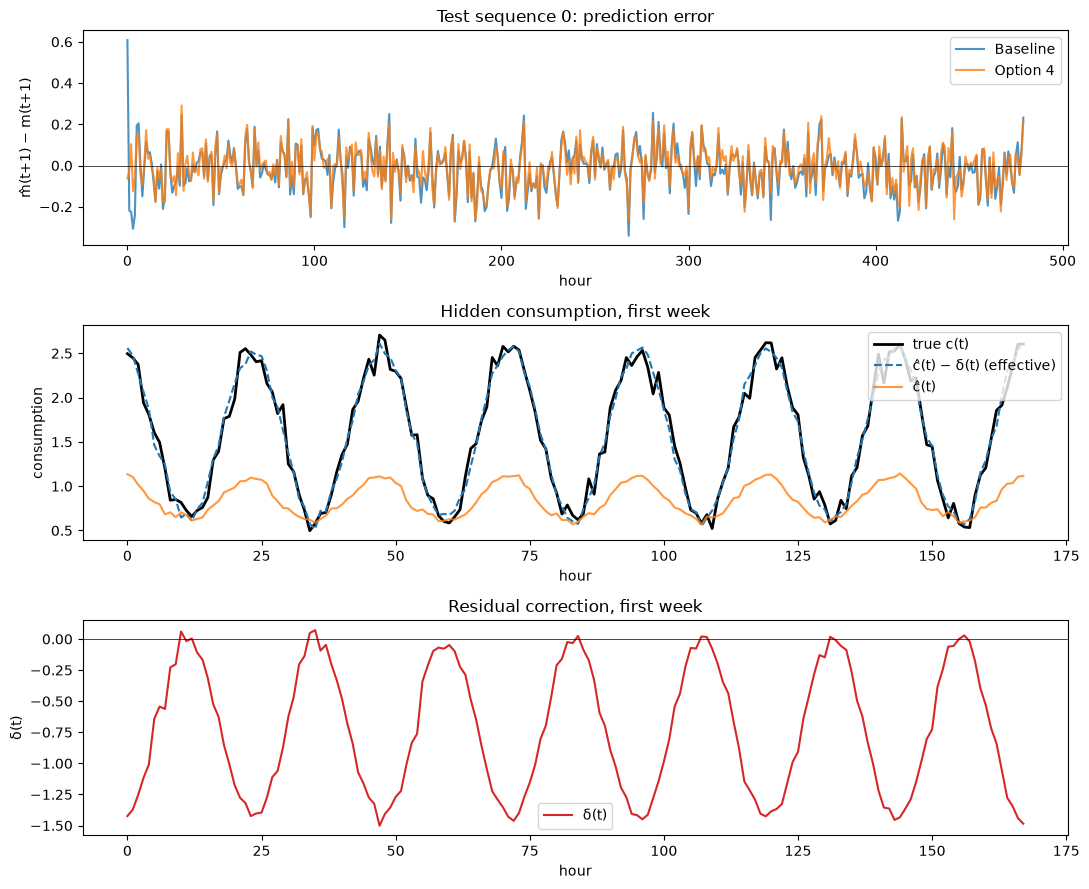

In [20]:
s = 0
week = slice(0, 168)
fig, axes = plt.subplots(3, 1, figsize=(11, 9))
axes[0].plot(pred_conv[s] - Y_te[s], label="Baseline", alpha=0.8)
axes[0].plot(pred_res[s] - Y_te[s], label="Option 4", alpha=0.8)
axes[0].axhline(0, color="k", lw=0.5)
axes[0].set(xlabel="hour", ylabel="m̂(t+1) − m(t+1)", title=f"Test sequence {s}: prediction error")
axes[0].legend()

axes[1].plot(C_te[s, week], label="true c(t)", color="k", lw=2)
axes[1].plot(eff_c[s, week], label="ĉ(t) − δ(t) (effective)", ls="--")
axes[1].plot(c_hat_te[s, week], label="ĉ(t)", alpha=0.8)
axes[1].set(xlabel="hour", ylabel="consumption", title="Hidden consumption, first week")
axes[1].legend(loc="upper right")

axes[2].plot(delta_te[s, week], label="δ(t)", color="tab:red")
axes[2].axhline(0, color="k", lw=0.5)
axes[2].set(xlabel="hour", ylabel="δ(t)", title="Residual correction, first week")
axes[2].legend()
plt.tight_layout()
plt.show()

<a id='10'></a>
## 9. Reflection questions

Answer using evidence from **your own** experiments — refer to your metrics table and plots, not just general reasoning.

**1. Why can a conventional LSTM violate a physical law, even after being trained to convergence on plenty of data?**

**Notes for the answer (key points and numbers from this notebook):**

- The MSE loss only measures the distance to the target. Two predictions equally far from the truth, one below and one above the physical limit `m + r − q`, get the same loss. The limit is not written in the architecture or in the loss.
- Evidence: on the test set the baseline has a physical error of 4.74e-05, and 0.017 % of its steps imply negative consumption. Option 4's balance structure gives 0.00e+00 and 0.000 %.
- Violations are rare here because the true `c` stays well above 0 compared with the baseline's error (test MAE 0.0948). They appear where `c` is small, near the boundary. They are still violations, and nothing in the model prevents more of them.
- Convergence doesn't fix this. The baseline's training loss went from 164.831 to 0.0152 but kept spiking late in training (around epochs 170 and 255 in the loss plot): the network moves freely in function space, and nothing anchors it to the law.
- More data or epochs make violations less frequent but never impossible. The guarantee has to come from the structure.

_Your answer:_

*(write here)*

**2. What is the difference between a soft constraint and a hard constraint? If you implemented Option 3 or 4, where would a soft constraint have gone instead, and how would training/evaluation have differed? If you implemented Option 2, reflect on how your choice of `λ` affected the accuracy/conservation trade-off.**

**Notes for the answer (key points and numbers from this notebook):**

- **Soft constraint:** the law is a penalty term in the loss, `L_pred + λ·L_physics`. It is satisfied approximately and only where the model was trained, it costs a hyperparameter `λ`, and it trades accuracy against consistency.
- **Hard constraint:** the law is built into the architecture, so it holds for any parameter values, before training and on unseen data. Example: in §6 the untrained Option 4 already matched the balance (gap 0.0e+00).
- Option 4 sits in between. The balance is hard, but `δ` is unconstrained, so conservation is approximate. Its physical error was 0.00e+00 on the test set because `ĉ − δ` stayed positive. That is a result of the fit, not a guarantee: `δ` reached a maximum `│δ│` of 1.654 and went slightly positive at the daily minima (§8 plot).
- Where a soft constraint could have gone instead:
  - (a) Replace the balance with a free `m̂` head plus the physics penalty (Option 2).
  - (b) Keep Option 4 and add a penalty `λ·δ²` that pushes the correction toward zero.
- How (b) would have differed: a `λ` to choose with several training runs, a smaller `δ` and a `ĉ` closer to the true `c` (here the MAE of `ĉ` alone is 0.763, against 0.080 for `ĉ − δ`). The evaluation would then also have to report how the physical error and the MSE change with `λ`.

_Your answer:_

*(write here)*

**3. How does physical knowledge act as an inductive bias? Explain how you would test this claim with the optional low-data ablation described in the assignment, and connect it to your own results if you ran it.**

**Notes for the answer (key points and numbers from this notebook):**

- Inductive bias means the assumptions built into a model that restrict which functions it can easily represent. Here the balance removes the large, known part of the target, `m + r − q` (target mean 154.82, std 16.60), and leaves only the small hidden term to learn.
- Evidence: the first-epoch training loss was 0.543 for Option 4 against 164.831 for the baseline. Option 4 settled at 0.0100, the noise floor set by `noise_c` (std 0.1, variance 0.01), while the baseline ended at 0.0152 with spikes.
- Test MSE: 0.0100 against 0.0169 (1.7x lower). The effective consumption `ĉ − δ` is recovered with MAE 0.080, about the noise level.
- Both models had the same data and parameter budget (5,025 vs 5,058 parameters). So this shows a better fit at full data, not yet data efficiency.
- **Ablation to test it** (not run here):
  - Train both models on 300, 150, 75, 30 and 10 training sequences, with the same settings and the same 100 test sequences. Recompute the normalization statistics on each subset.
  - Plot test MSE against the training-set size, on log axes.
  - Expected: Option 4 degrades much more slowly, so the gap widens as data shrinks. Repeating with a few seeds would show the spread.

_Your answer:_

*(write here)*

**4. In what other application domains could this idea (predicting an unknown residual term and reconstructing the target analytically) be useful? Give at least one concrete example outside of hydrology.**

**Notes for the answer (key points and numbers from this notebook):**

- The pattern carries over whenever there is a known accounting identity with one unknown term: predict the unknown term and compute the target from the identity.
- **Battery state of charge:** `SoC(t+1) = SoC(t) + charge in − charge out − losses`. Predict the losses (self-discharge, heat) from temperature and age.
- **Building heat balance:** next indoor temperature from measured heating and ventilation, plus a learned term for unmeasured gains (occupants, sun).
- **Inventory and retail:** `stock(t+1) = stock(t) + deliveries − recorded sales − shrinkage`. Predict the shrinkage (theft, spoilage).
- **Epidemic compartment models (SIR):** the total population is conserved between compartments. Predict a time-varying transmission rate, and let the compartment equations give the counts.
- **Traffic on a road segment:** vehicles in = vehicles out + change in the number on the segment. Predict unmetered on- and off-ramp flows.
- **Chemical reactors:** a mass or atom balance closes, and the network learns the reaction rate.

_Your answer:_

*(write here)*

**5. How could causality, rather than mass conservation, be incorporated into a neural network architecture? What would "hard enforcement" of a causal constraint even mean, compared to enforcing a conservation law?**

**Notes for the answer (key points and numbers from this notebook):**

- Temporal causality is already hard-enforced here: the LSTM's prediction at step `t` uses only `x(0) … x(t)`, never the future. Causal masking in transformers and causal convolutions do the same.
- Structural causality goes further: a causal graph says which variables may affect which. Enforcing it means restricting the inputs of each part of the network to the parents of its node in the graph (masked weights, one sub-network per variable, as in structural causal models). For example, `ĉ` could be computed only from temperature, hour and day, never from the valve outflow `q`.
- What "hard" would mean: for any parameter values, the model cannot represent a dependency the graph forbids, because the path does not exist. A soft version would penalize such dependencies (gradients or attributions) in the loss.
- Differences from conservation:
  - A conservation law is an equality on the values, checkable at every step (our physical error).
  - A causal constraint is about the structure of dependencies and the effect of interventions. A single prediction cannot show whether it holds; it is tested by changing an input and seeing what moves.
  - The graph must be assumed or justified. Observational data alone often cannot separate candidate graphs, whereas mass conservation is known exactly.
- A possible check in this notebook: change future inputs of a test sequence and verify that past predictions don't move.

_Your answer:_

*(write here)*

<a id='11'></a>
## 11. Before you submit

**Common pitfalls to double-check:**
- The true `c(t)` never leaks into either model's inputs.
- Train/test split is by *sequence*, not by timestep.
- Normalization statistics come from the training split only.
- Your model's mass computation (Options 3/4) or physics loss term (Option 2) uses raw, unnormalized `m, r, q`.
- Both models used the same hidden size, optimizer, learning rate, epochs, and batch size.
- You didn't reuse a JAX PRNG key without splitting it first.

**Deliverables checklist:**
- [x] Reproducible notebook, seeded end-to-end with explicit `PRNGKey`s
- [x] Synthetic data generator with a sanity-check plot of at least one simulated sequence
- [x] Baseline LSTM implementation (Option 1)
- [x] Your chosen model implementation (Option 2, 3, or 4 -- matching your Phase A plan)
- [x] Both models trained under identical settings, with training-loss curves plotted together
- [x] Metrics table (MSE, MAE, physical error, training time) on the test set for both models
- [ ] *(recommended, optional bonus)* Low-data ablation plot (test MSE vs. training-set size)
- [ ] Written answers to all five reflection questions, grounded in your own results

**Final checks.** The pitfalls above, re-checked with asserts on the objects actually used for training: the batches hold the 6 normalized features plus raw `m, r, q` only (never `C`); train and test are disjoint sequence ranges; the statistics come from the training split; both models share hidden size, optimizer, epochs and batch size.

In [21]:
# 1. No leak of c(t): 6 input features, and the only extra batch arrays are the raw m, r, q
assert Xn_tr.shape[-1] == 6
assert set(extra_conv) == set() and set(extra_res) == {"m", "r", "q"}
assert all(not jnp.allclose(v, C_tr) for v in extra_res.values())
# 2. Split by sequence: disjoint, contiguous sequence ranges
assert jnp.array_equal(X_tr, X[:n_train]) and jnp.array_equal(X_te, X[n_train:]) and len(X_tr) + len(X_te) == len(X)
# 3. Statistics from the training split only
assert jnp.allclose(x_mean, X_tr.reshape(-1, 6).mean(0)) and jnp.allclose(y_mean, Y_tr.mean())
# 4. Raw units in the balance: Option 4's m_pred equals the balance computed with raw test values
assert float(jnp.max(jnp.abs(pred_res - (m_te + r_te - q_te - c_hat_te + delta_te)))) < 1e-3
# 5. Identical training conditions
assert conv_model.hidden_size == res_model.hidden_size == HIDDEN_SIZE
assert len(conv_losses) == len(res_losses) == EPOCHS
print("All checks passed.")

All checks passed.
